### Carga de librerías

In [1]:
import os
import numpy as np
import pandas as pd
from math import pi
import seaborn as sns
import No_Supervisados as ns
import matplotlib.pyplot as plt
from prince import PCA as PCA_Prince
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from scipy.spatial.distance import pdist
from scipy.cluster.hierarchy import dendrogram, ward, single, complete, average, linkage, fcluster
from Sem3_MD_Funciones import ACP
import warnings
warnings.filterwarnings('ignore')

In [2]:
pd.options.display.max_rows = 10

## 1. Descripción del set de datos y tipos de variables

In [3]:
datos = pd.read_csv('Wholesale customers data.csv', delimiter=',', decimal=".")
datos

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185
...,...,...,...,...,...,...,...,...
435,1,3,29703,12051,16027,13135,182,2204
436,1,3,39228,1431,764,4510,93,2346
437,2,3,14531,15488,30243,437,14841,1867
438,1,3,10290,1981,2232,1038,168,2125


In [4]:
datos.shape

(440, 8)

In [5]:
datos.dtypes

Channel             int64
Region              int64
Fresh               int64
Milk                int64
Grocery             int64
Frozen              int64
Detergents_Paper    int64
Delicassen          int64
dtype: object

**Descripción del set de datos:** el *Wholesale Customers Dataset* (repositorio UCI) contiene el gasto anual, en unidades monetarias (m.u.), de **440 clientes** de un distribuidor mayorista en Portugal, en distintas categorías de productos. No posee una variable objetivo, por lo que se trata de un problema de **aprendizaje no supervisado**: el objetivo es encontrar grupos (segmentos) de clientes con patrones de compra similares.

| Variable | Tipo | Descripción | Uso en el análisis |
|---|---|---|---|
| Channel | Categórica nominal (codificada 1-2) | Canal: 1 = Horeca (hoteles, restaurantes, cafés), 2 = Retail (minoristas) | Descriptiva: interpretar los clústeres |
| Region | Categórica nominal (codificada 1-3) | Región: 1 = Lisboa, 2 = Oporto, 3 = Otra | Descriptiva: interpretar los clústeres |
| Fresh | Numérica continua | Gasto anual en productos frescos | Variable de clusterización |
| Milk | Numérica continua | Gasto anual en lácteos | Variable de clusterización |
| Grocery | Numérica continua | Gasto anual en abarrotes | Variable de clusterización |
| Frozen | Numérica continua | Gasto anual en congelados | Variable de clusterización |
| Detergents_Paper | Numérica continua | Gasto anual en detergentes y productos de papel | Variable de clusterización |
| Delicassen | Numérica continua | Gasto anual en productos delicatessen | Variable de clusterización |

Aunque Python lee `Channel` y `Region` como `int64`, en realidad son **categóricas**: sus números son solo códigos y no tiene sentido calcular distancias o promedios sobre ellos. Por eso se recodifican con la función `recodificar` vista en clase.

### Recodificación de variables categóricas

In [6]:
datos["Channel"] = ns.recodificar(datos["Channel"], {1:'Horeca', 2:'Retail'})
datos["Region"] = ns.recodificar(datos["Region"], {1:'Lisboa', 2:'Oporto', 3:'Otra'})
datos.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,Retail,Otra,12669,9656,7561,214,2674,1338
1,Retail,Otra,7057,9810,9568,1762,3293,1776
2,Retail,Otra,6353,8808,7684,2405,3516,7844
3,Horeca,Otra,13265,1196,4221,6404,507,1788
4,Retail,Otra,22615,5410,7198,3915,1777,5185


In [7]:
datos.dtypes

Channel             object
Region              object
Fresh                int64
Milk                 int64
Grocery              int64
Frozen               int64
Detergents_Paper     int64
Delicassen           int64
dtype: object

## 2. Análisis exploratorio
### Valores nulos y duplicados

In [8]:
print("Valores nulos por variable:\n", datos.isnull().sum())
print("\nRegistros duplicados:", datos.duplicated().sum())

Valores nulos por variable:
 Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

Registros duplicados: 0


El set de datos **no presenta valores nulos ni registros duplicados**, por lo que no es necesario imputar ni eliminar observaciones.

### Estadísticas descriptivas de las variables numéricas

In [9]:
datos_numericos = datos.select_dtypes(include=["number"])
datos_numericos.describe().round(2)

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.00,440.00,440.00,440.00,440.00,440.00
mean,12000.30,5796.27,7951.28,3071.93,2881.49,1524.87
std,12647.33,7380.38,9503.16,4854.67,4767.85,2820.11
min,3.00,55.00,3.00,25.00,3.00,3.00
25%,3127.75,1533.00,2153.00,742.25,256.75,408.25
50%,8504.00,3627.00,4755.50,1526.00,816.50,965.50
75%,16933.75,7190.25,10655.75,3554.25,3922.00,1820.25
max,112151.00,73498.00,92780.00,60869.00,40827.00,47943.00


- Todas las variables presentan una **media bastante mayor que la mediana** (por ejemplo `Fresh`: media 12 000 vs mediana 8 504; `Detergents_Paper`: 2 881 vs 816), lo cual indica distribuciones **asimétricas a la derecha**: la mayoría de clientes compra poco y unos pocos compran montos muy altos.
- Los máximos son muy superiores al percentil 75 (`Fresh` llega a 112 151 y `Delicassen` a 47 943), lo que anticipa la presencia de **valores atípicos**.
- Las escalas son muy distintas: `Fresh` tiene una desviación estándar de ~12 600, mientras que `Delicassen` ~2 800.

### Frecuencias de las variables categóricas

In [10]:
print(datos["Channel"].value_counts())
print()
print(datos["Region"].value_counts())

Channel
Horeca    298
Retail    142
Name: count, dtype: int64

Region
Otra      316
Lisboa     77
Oporto     47
Name: count, dtype: int64


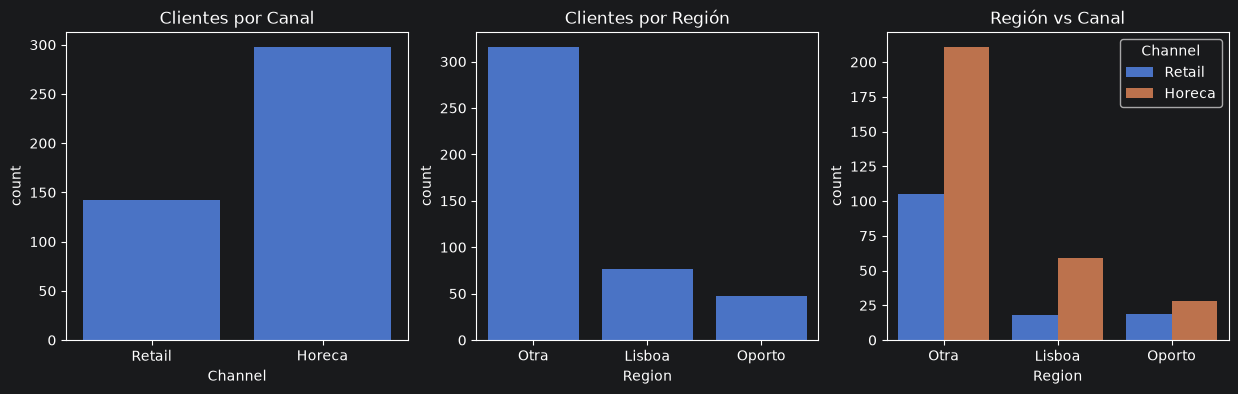

In [11]:
fig, ax = plt.subplots(1, 3, figsize = (15,4), dpi = 100)
sns.countplot(x = "Channel", data = datos, ax = ax[0])
ax[0].set_title("Clientes por Canal")
sns.countplot(x = "Region", data = datos, ax = ax[1])
ax[1].set_title("Clientes por Región")
sns.countplot(x = "Region", hue = "Channel", data = datos, ax = ax[2])
ax[2].set_title("Región vs Canal")
plt.show()

- El canal **Horeca** concentra la mayoría de clientes (298, 68 %) frente a **Retail** (142, 32 %).
- La región **"Otra"** agrupa 316 clientes (72 %); Lisboa tiene 77 y Oporto 47.
- La proporción de clientes Horeca predomina en las tres regiones (77 % en Lisboa, 60 % en Oporto y 67 % en "Otra"), aunque Oporto tiene proporcionalmente más clientes Retail.

### Distribución de las variables numéricas (histogramas)

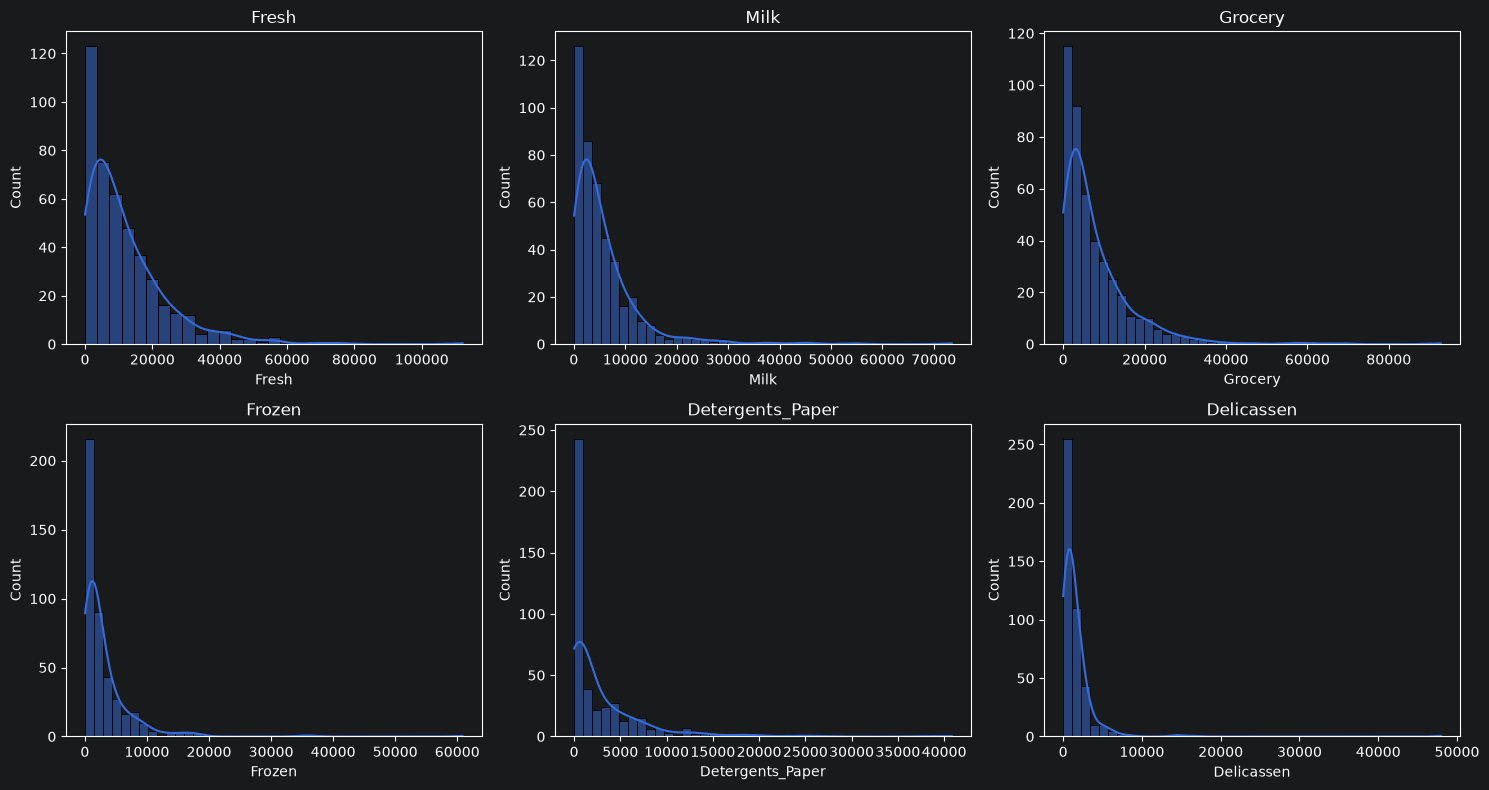

In [12]:
fig, ax = plt.subplots(2, 3, figsize = (15,8), dpi = 100)
for i, col in enumerate(datos_numericos.columns):
    sns.histplot(datos_numericos[col], kde = True, ax = ax[i//3, i%3])
    ax[i//3, i%3].set_title(col)
plt.tight_layout()
plt.show()

Los histogramas confirman que todas las variables de gasto tienen una **fuerte asimetría positiva** (cola larga hacia la derecha): la gran mayoría de clientes se concentra en montos bajos y unos pocos alcanzan montos muy altos.

### Diagramas de caja (valores atípicos)

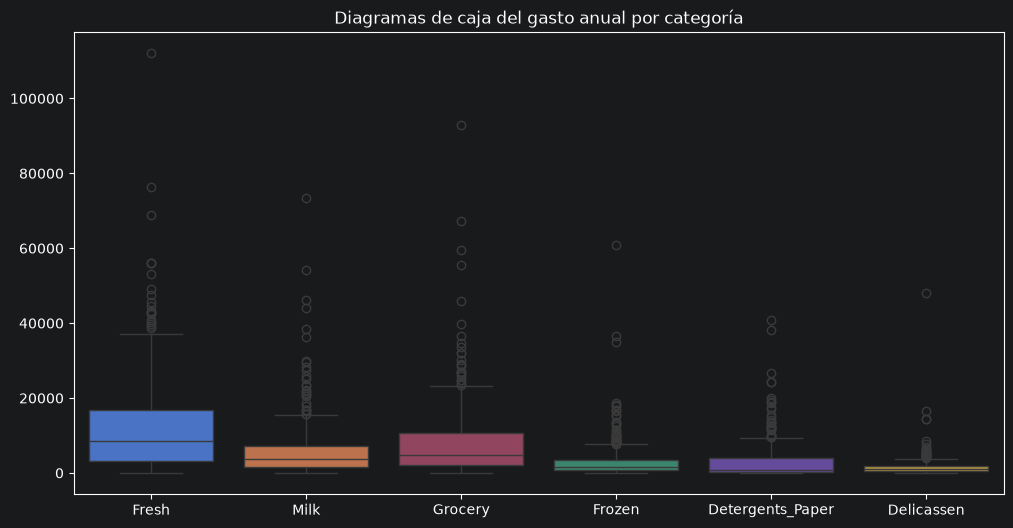

In [13]:
fig, ax = plt.subplots(1, 1, figsize = (12,6), dpi = 100)
sns.boxplot(data = datos_numericos, ax = ax)
ax.set_title("Diagramas de caja del gasto anual por categoría")
plt.show()

In [14]:
# Cantidad de valores atípicos por variable (criterio del rango intercuartílico)
Q1 = datos_numericos.quantile(0.25)
Q3 = datos_numericos.quantile(0.75)
RIC = Q3 - Q1
((datos_numericos < (Q1 - 1.5 * RIC)) | (datos_numericos > (Q3 + 1.5 * RIC))).sum()

Fresh               20
Milk                28
Grocery             24
Frozen              43
Detergents_Paper    30
Delicassen          27
dtype: int64

Todas las variables presentan **valores atípicos** (entre 20 y 43 por variable según el criterio de 1.5 × RIC); `Frozen` es la que tiene más (43) y `Delicassen` tiene el caso más extremo. Estos clientes no son errores de captura sino **clientes grandes reales**, por lo que se mantienen en el análisis.

### Gasto por canal

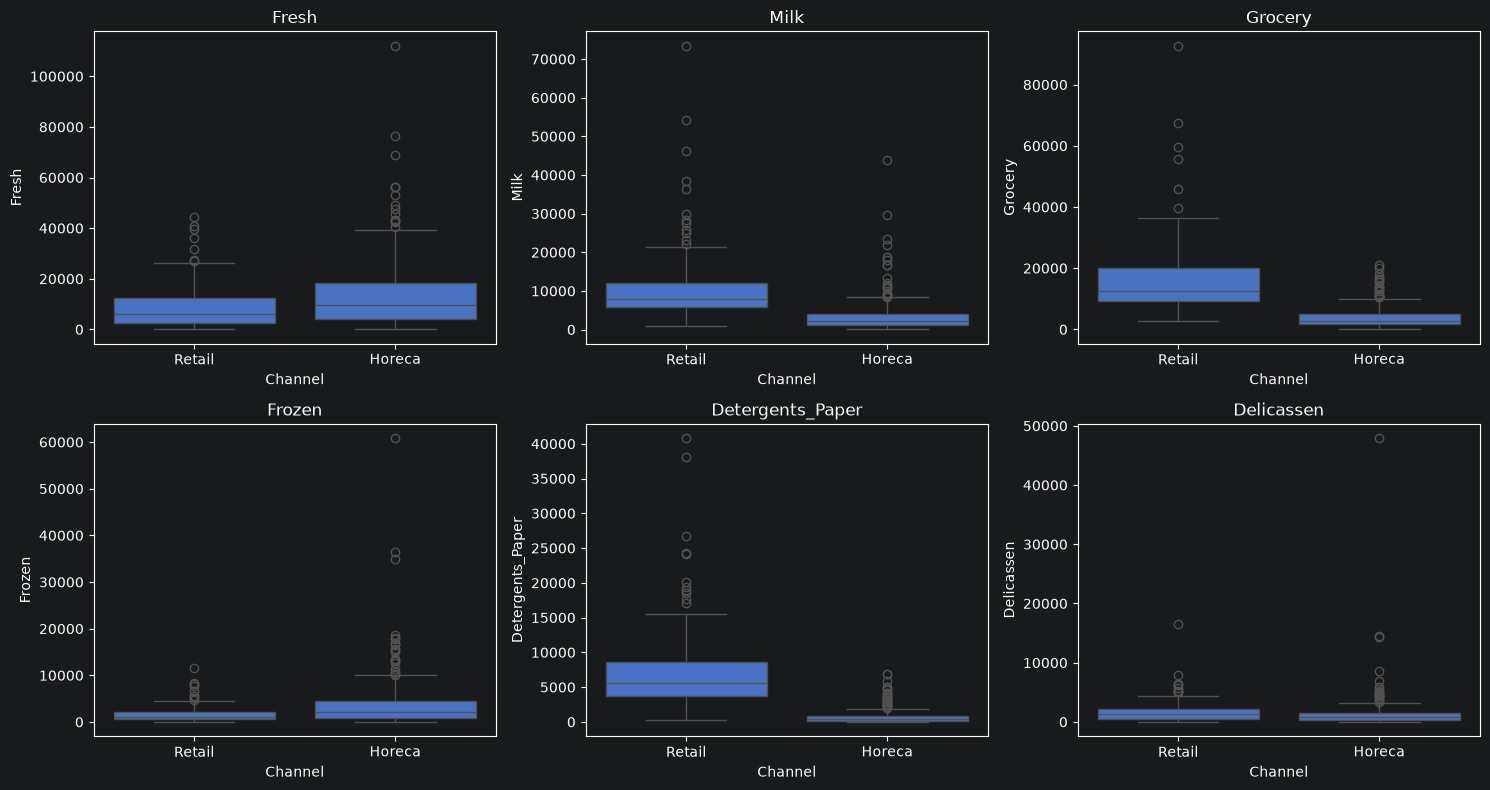

In [15]:
fig, ax = plt.subplots(2, 3, figsize = (15,8), dpi = 100)
for i, col in enumerate(datos_numericos.columns):
    sns.boxplot(x = "Channel", y = col, data = datos, ax = ax[i//3, i%3])
    ax[i//3, i%3].set_title(col)
plt.tight_layout()
plt.show()

In [16]:
datos.groupby("Channel")[datos_numericos.columns].mean().round(2)

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Channel,,,,,,
Horeca,13475.56,3451.72,3962.14,3748.25,790.56,1415.96
Retail,8904.32,10716.50,16322.85,1652.61,7269.51,1753.44


Existe una diferencia clara en el patrón de compra según el canal:
- **Horeca** gasta más en `Fresh` (13 476) y `Frozen` (3 748), algo coherente con restaurantes y hoteles que preparan comida.
- **Retail** gasta mucho más en `Grocery` (16 323 vs 3 962), `Milk` (10 717 vs 3 452) y `Detergents_Paper` (7 270 vs 791), que son productos de reventa típicos de un supermercado.

Esto sugiere que los clústeres podrían reflejar en buena medida el canal del cliente.

### Matriz de correlación

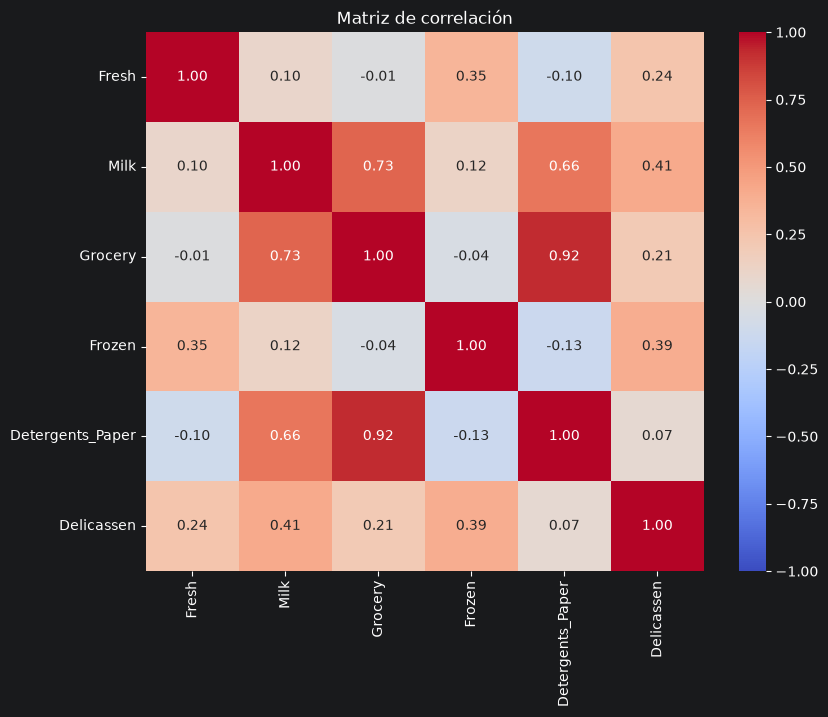

In [17]:
corr = datos_numericos.corr()
fig, ax = plt.subplots(1, 1, figsize = (9,7), dpi = 100)
sns.heatmap(corr, annot = True, fmt = ".2f", cmap = "coolwarm", vmin = -1, vmax = 1, ax = ax)
ax.set_title("Matriz de correlación")
plt.show()

- **Grocery y Detergents_Paper** tienen una correlación muy alta (**0.92**), y ambas se correlacionan fuertemente con **Milk** (0.73 y 0.66). Estas tres variables forman un bloque asociado a las compras tipo *Retail*.
- **Fresh, Frozen y Delicassen** tienen correlaciones positivas moderadas entre sí (0.24 a 0.39), formando un segundo bloque asociado a *Horeca*.
- Entre ambos bloques las correlaciones son cercanas a 0.

### Estandarización de los datos

**¿Por qué estandarizar?** Las variables de gasto están en la misma unidad monetaria, pero sus escalas y varianzas son muy diferentes (por ejemplo, `Fresh` tiene una desviación estándar mucho mayor que `Delicassen`). Tanto K-medias como la clusterización jerárquica utilizan la **distancia euclidiana**, por lo que, sin estandarizar, las variables con mayor varianza dominarían el cálculo de las distancias y los grupos se formarían prácticamente solo por ellas. Con `StandardScaler` cada variable queda con media 0 y desviación estándar 1, de modo que todas aportan de forma equitativa al análisis.

Se decidió **no eliminar los valores atípicos**, ya que corresponden a clientes reales con compras muy grandes (información valiosa para el negocio); sin embargo, se debe tener presente que pueden formar grupos pequeños propios.

Las variables categóricas `Channel` y `Region` **no se utilizan para formar los clústeres**: se reservan para describir e interpretar los grupos obtenidos.

In [18]:
scaler = StandardScaler()
datos_std = pd.DataFrame(scaler.fit_transform(datos_numericos), columns = datos_numericos.columns)
datos_std.describe().round(2)

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.00,440.00,440.00,440.00,440.00,440.00
mean,-0.00,0.00,-0.00,0.00,0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00
min,-0.95,-0.78,-0.84,-0.63,-0.60,-0.54
25%,-0.70,-0.58,-0.61,-0.48,-0.55,-0.40
50%,-0.28,-0.29,-0.34,-0.32,-0.43,-0.20
75%,0.39,0.19,0.28,0.10,0.22,0.10
max,7.93,9.18,8.94,11.92,7.97,16.48


### Análisis en Componentes Principales (ACP)

In [19]:
acp = ACP(datos_std, n_componentes = 6)
acp.var_explicada

array([44.08289288, 28.37639953, 12.3344129 ,  9.39550375,  4.7612724 ,
        1.04951854])

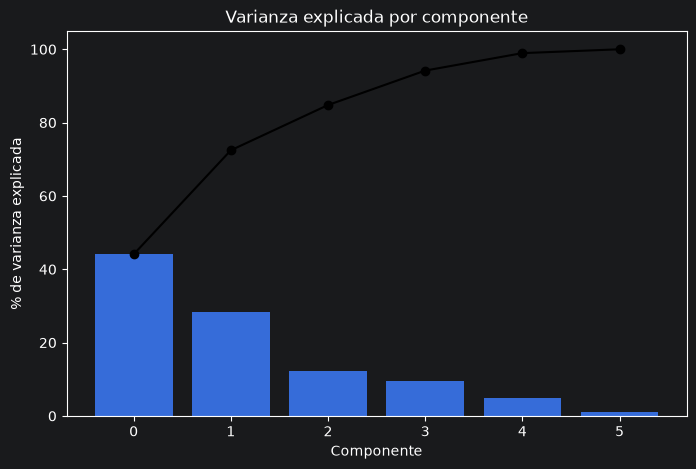

In [20]:
fig, ax = plt.subplots(1, 1, figsize = (8,5), dpi = 100)
plt.bar(range(len(acp.var_explicada)), acp.var_explicada)
plt.plot(range(len(acp.var_explicada)), np.cumsum(acp.var_explicada), 'o-', c = 'k')
plt.xlabel("Componente")
plt.ylabel("% de varianza explicada")
plt.title("Varianza explicada por componente")
plt.show()

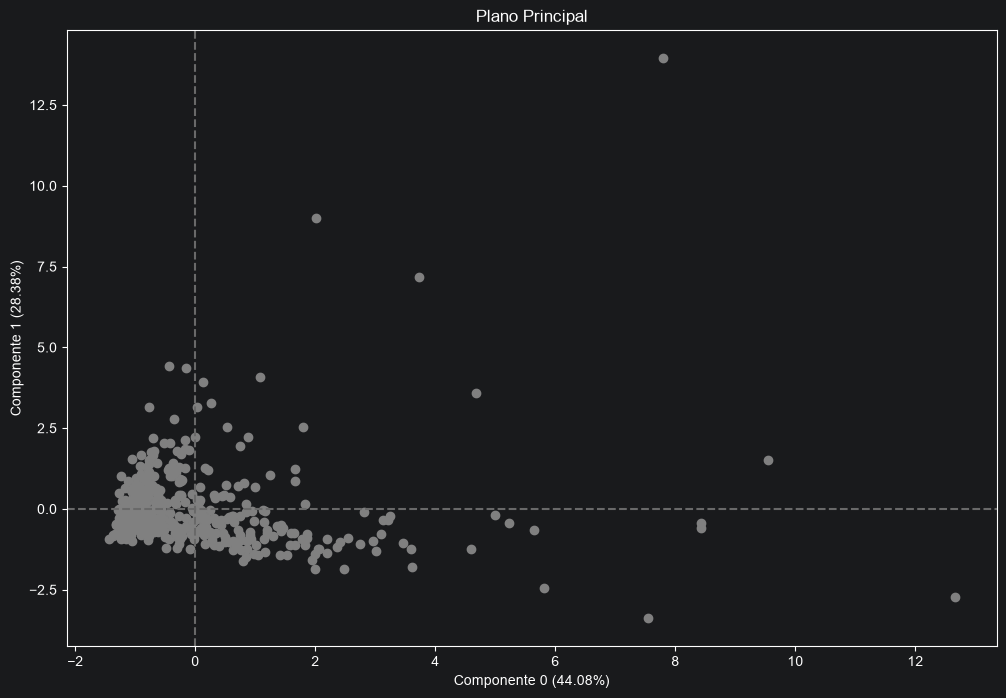

In [21]:
fig, ax = plt.subplots(1, 1, figsize = (12,8), dpi = 100)
acp.plot_plano_principal(ind_labels = False)
plt.show()

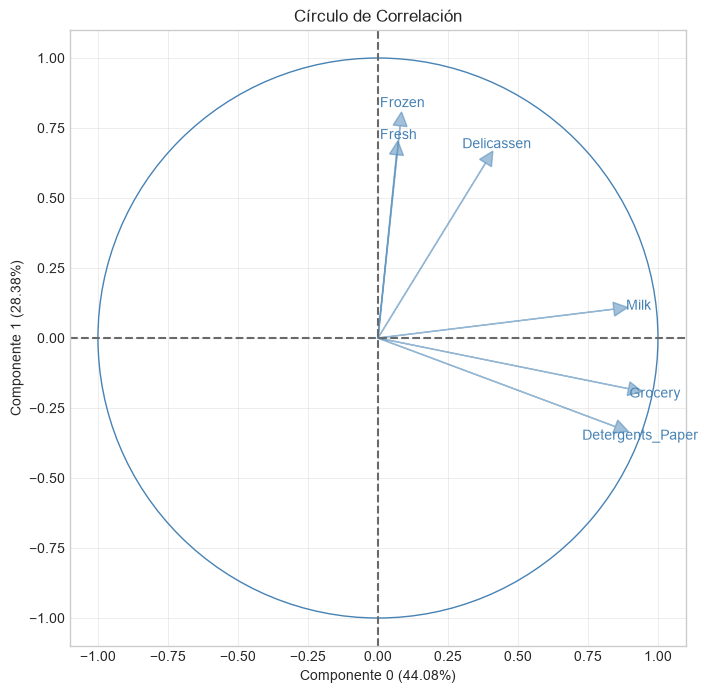

In [22]:
fig, ax = plt.subplots(1, 1, figsize = (8,8), dpi = 100)
acp.plot_circulo()
plt.show()

- Las dos primeras componentes explican **72.46 %** de la varianza (44.08 % + 28.38 %), por lo que el plano principal representa bien a los datos.
- En el círculo de correlación se observan los dos bloques identificados en la matriz de correlación: **Grocery, Detergents_Paper y Milk** se asocian principalmente con la **Componente 0** (eje de compras tipo *Retail*), mientras que **Fresh, Frozen y Delicassen** se asocian con la **Componente 1** (eje de compras tipo *Horeca*).
- En el plano principal la mayoría de clientes se concentra cerca del origen y unos pocos se alejan mucho; estos son los clientes atípicos de gran volumen.

## 3. Clusterización K-medias
### Método del codo para escoger K

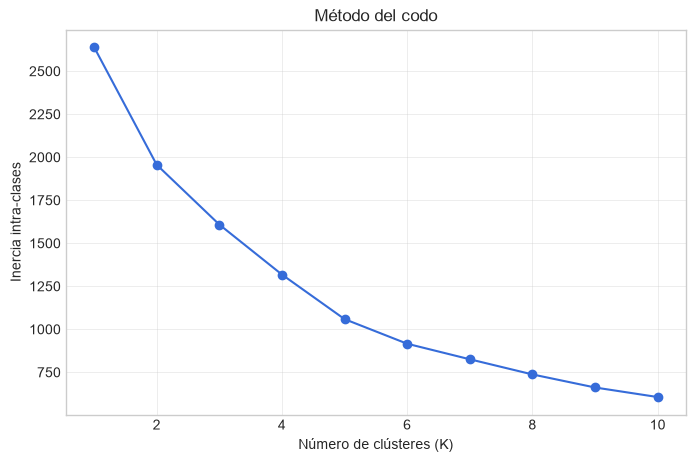

In [23]:
inercias = []
for k in range(1, 11):
    kmedias = KMeans(n_clusters = k, n_init = 10, random_state = 42)
    kmedias.fit(datos_std)
    inercias.append(kmedias.inertia_)

fig, ax = plt.subplots(1, 1, figsize = (8,5), dpi = 100)
plt.plot(range(1, 11), inercias, 'o-')
plt.xlabel("Número de clústeres (K)")
plt.ylabel("Inercia intra-clases")
plt.title("Método del codo")
plt.show()

La inercia cae fuertemente de K = 1 a K = 2 y luego disminuye de forma más gradual, sin un codo muy marcado (algo común cuando hay muchos valores atípicos). Los valores candidatos están aproximadamente entre **K = 3 y K = 5**, por lo que la decisión se complementa revisando el tamaño de los grupos.

### Tamaño de los grupos según K
Además del codo, se revisa cuántos clientes quedan en cada grupo para distintos valores de K, ya que por los valores atípicos algunos valores de K generan grupos de 1 o 2 clientes que no son útiles para el negocio.

In [24]:
for k in range(2, 8):
    kmedias = KMeans(n_clusters = k, n_init = 10, random_state = 42)
    kmedias.fit(datos_std)
    print("K =", k, "->", sorted(pd.Series(kmedias.labels_).value_counts().tolist(), reverse = True))

K = 2 -> [389, 51]
K = 3 -> [393, 45, 2]
K = 4 -> [315, 110, 10, 5]
K = 5 -> [270, 96, 63, 10, 1]
K = 6 -> [280, 98, 49, 10, 2, 1]
K = 7 -> [258, 104, 49, 21, 5, 2, 1]


- Con **K = 2 y K = 3** los atípicos dominan: K = 3 produce un grupo de solo **2 clientes**, y el grupo principal tiene casi 400 clientes, lo que aporta poca segmentación.
- Con **K = 4** se obtienen dos grupos grandes y bien diferenciados (315 y 110 clientes) más dos grupos pequeños (10 y 5) que aíslan a los clientes de gran volumen.
- Con K ≥ 5 empiezan a aparecer grupos de 1 o 2 clientes.

Por lo tanto, se escoge **K = 4**.

In [25]:
kmedias = KMeans(n_clusters = 4, n_init = 10, random_state = 42)
kmedias.fit(datos_std)
grupos_km = kmedias.predict(datos_std)
grupos_km

array([1, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1,
       1, 3, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0,
       0, 0, 0, 2, 0, 0, 1, 1, 1, 0, 1, 1, 2, 0, 1, 1, 1, 2, 1, 0, 1, 2,
       1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 2, 2, 3,
       1, 1, 1, 1, 2, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0,
       1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0,
       1, 1, 1, 1, 1, 3, 0, 3, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0,
       1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 2, 1, 0, 0, 0, 0, 1, 0, 1,
       1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 0, 1, 1, 1, 1, 1, 2, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1,

In [26]:
pd.Series(grupos_km).value_counts().sort_index()

0    110
1    315
2     10
3      5
Name: count, dtype: int64

### Centros de los clústeres (datos estandarizados)

In [27]:
centros = np.array(pd.concat([ns.centroide(0, datos_std, grupos_km),
                              ns.centroide(1, datos_std, grupos_km),
                              ns.centroide(2, datos_std, grupos_km),
                              ns.centroide(3, datos_std, grupos_km)]))
centros

array([[-5.07313178e-01,  5.85562912e-01,  8.09715977e-01,
        -3.24183103e-01,  8.04181619e-01,  8.31483192e-02],
       [ 1.19108342e-01, -3.73267987e-01, -4.32646239e-01,
         4.11398768e-02, -4.26078939e-01, -1.41205792e-01],
       [ 3.13830315e-01,  3.92190593e+00,  4.27561037e+00,
        -3.57419457e-03,  4.61816580e+00,  5.03365339e-01],
       [ 3.02940375e+00,  2.78968723e+00,  8.91740814e-01,
         4.54736442e+00, -8.53540936e-02,  6.05997120e+00]])

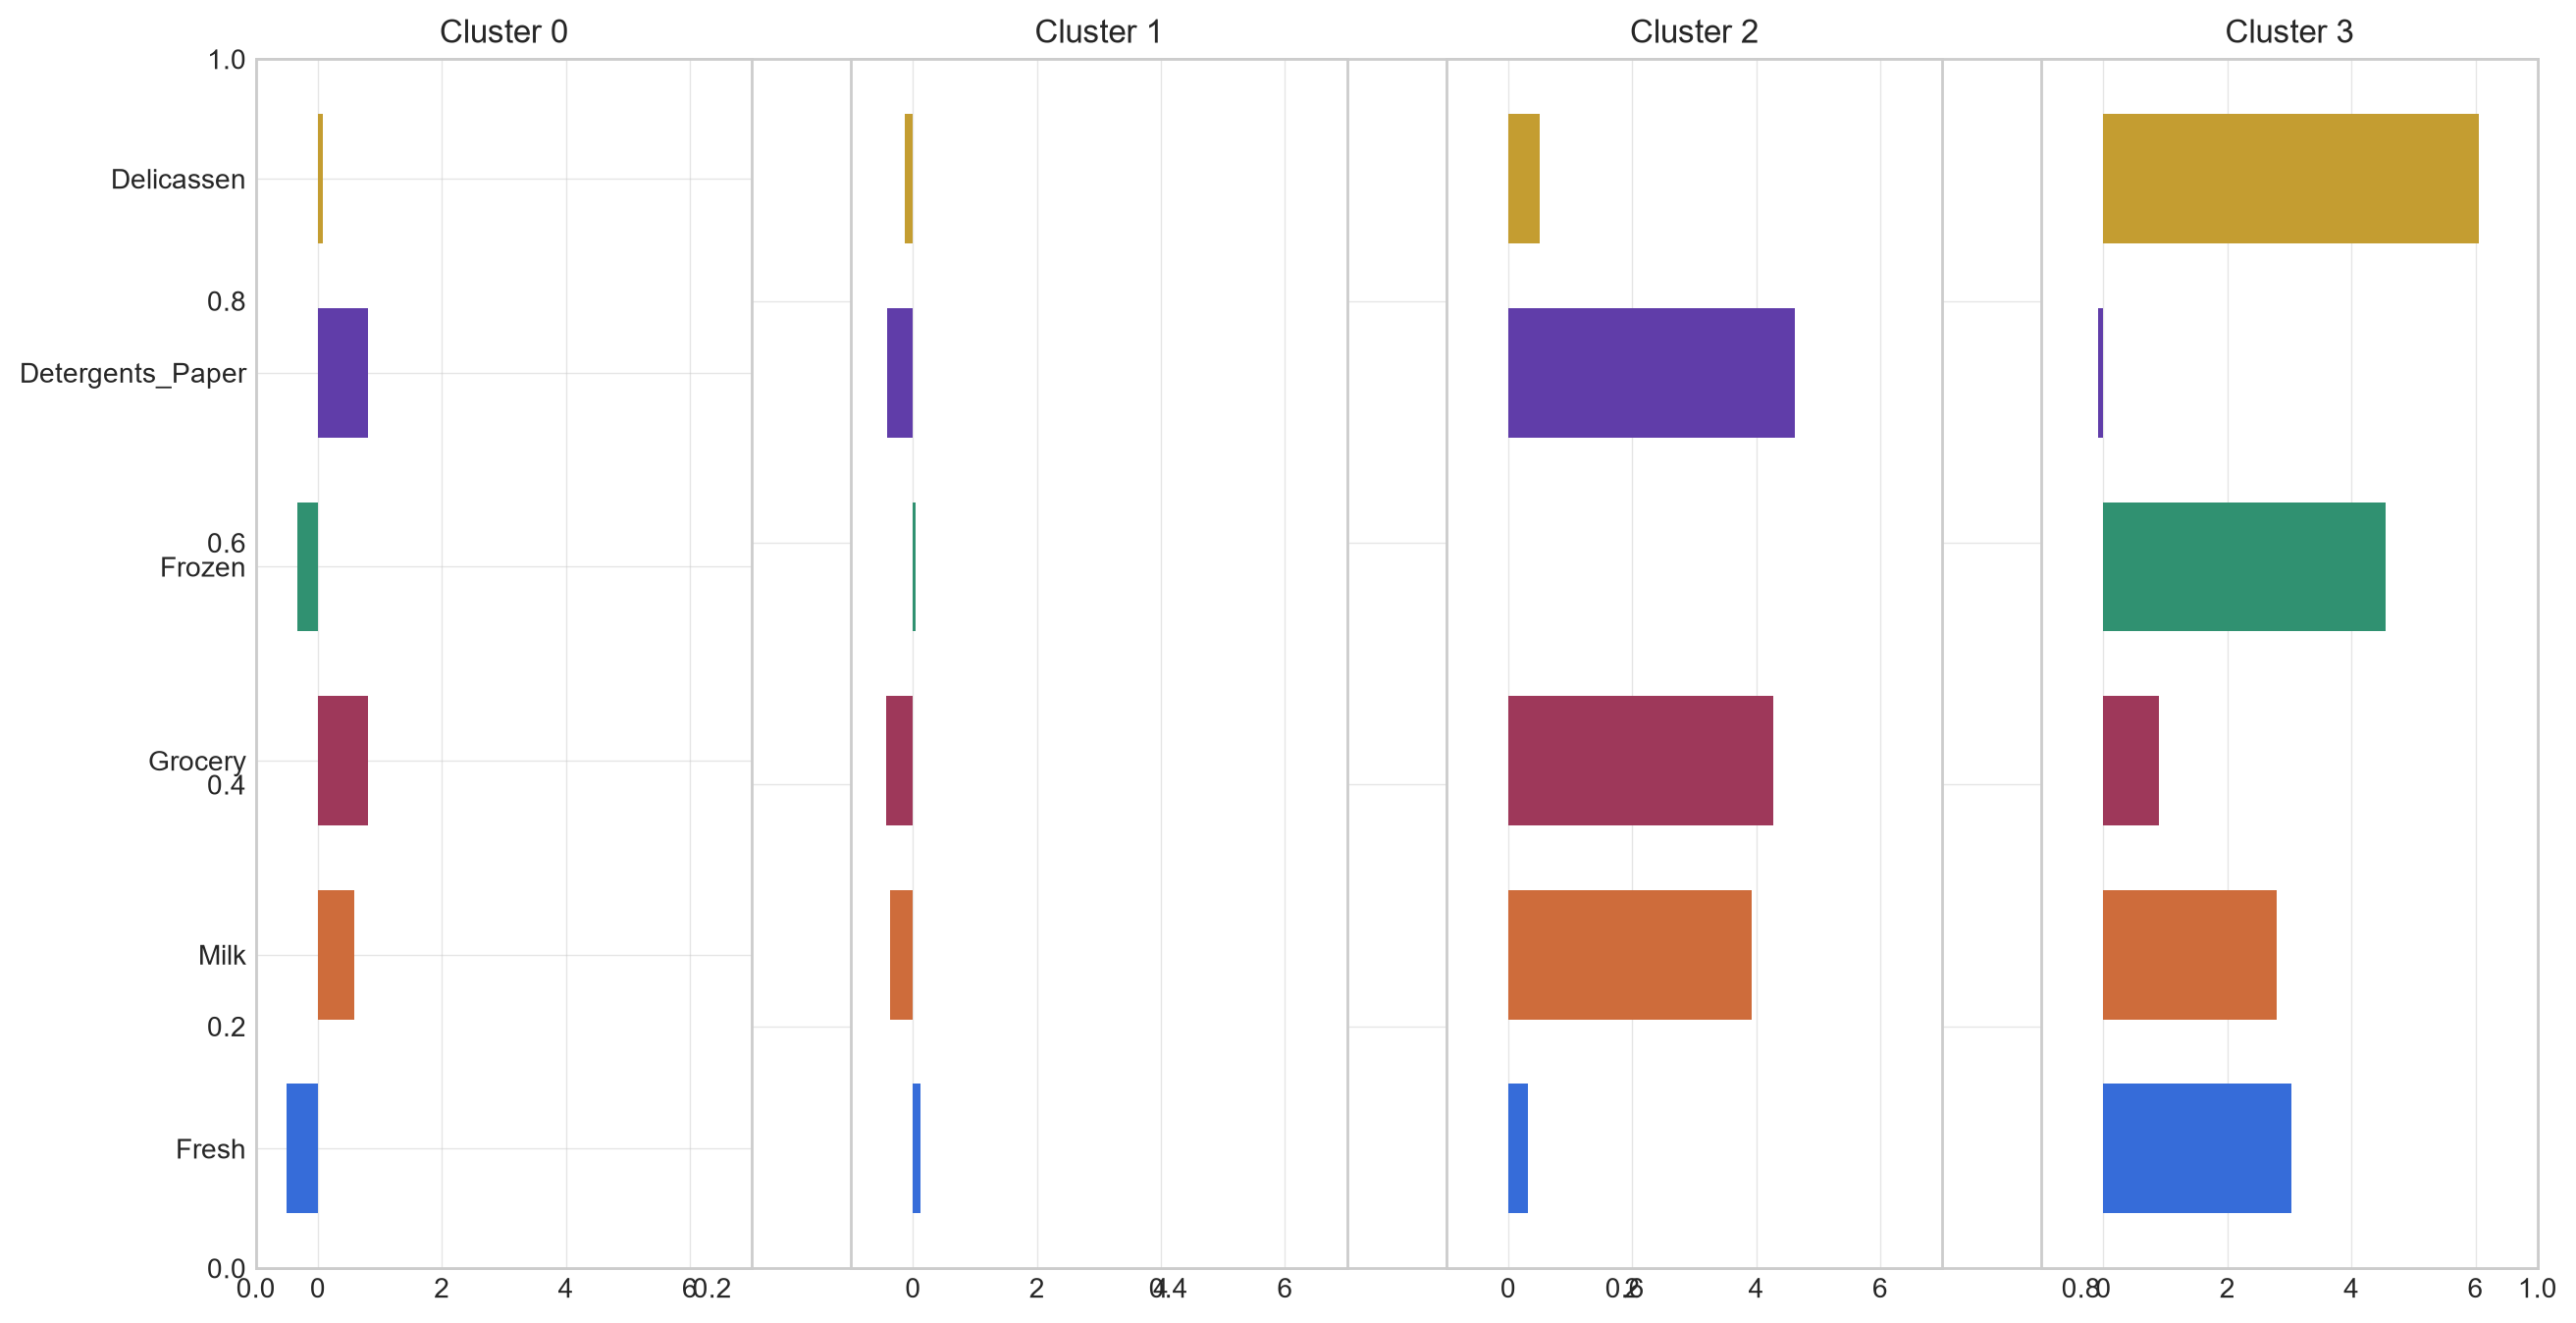

In [28]:
ns.bar_plot(centros, datos_std.columns)
plt.show()

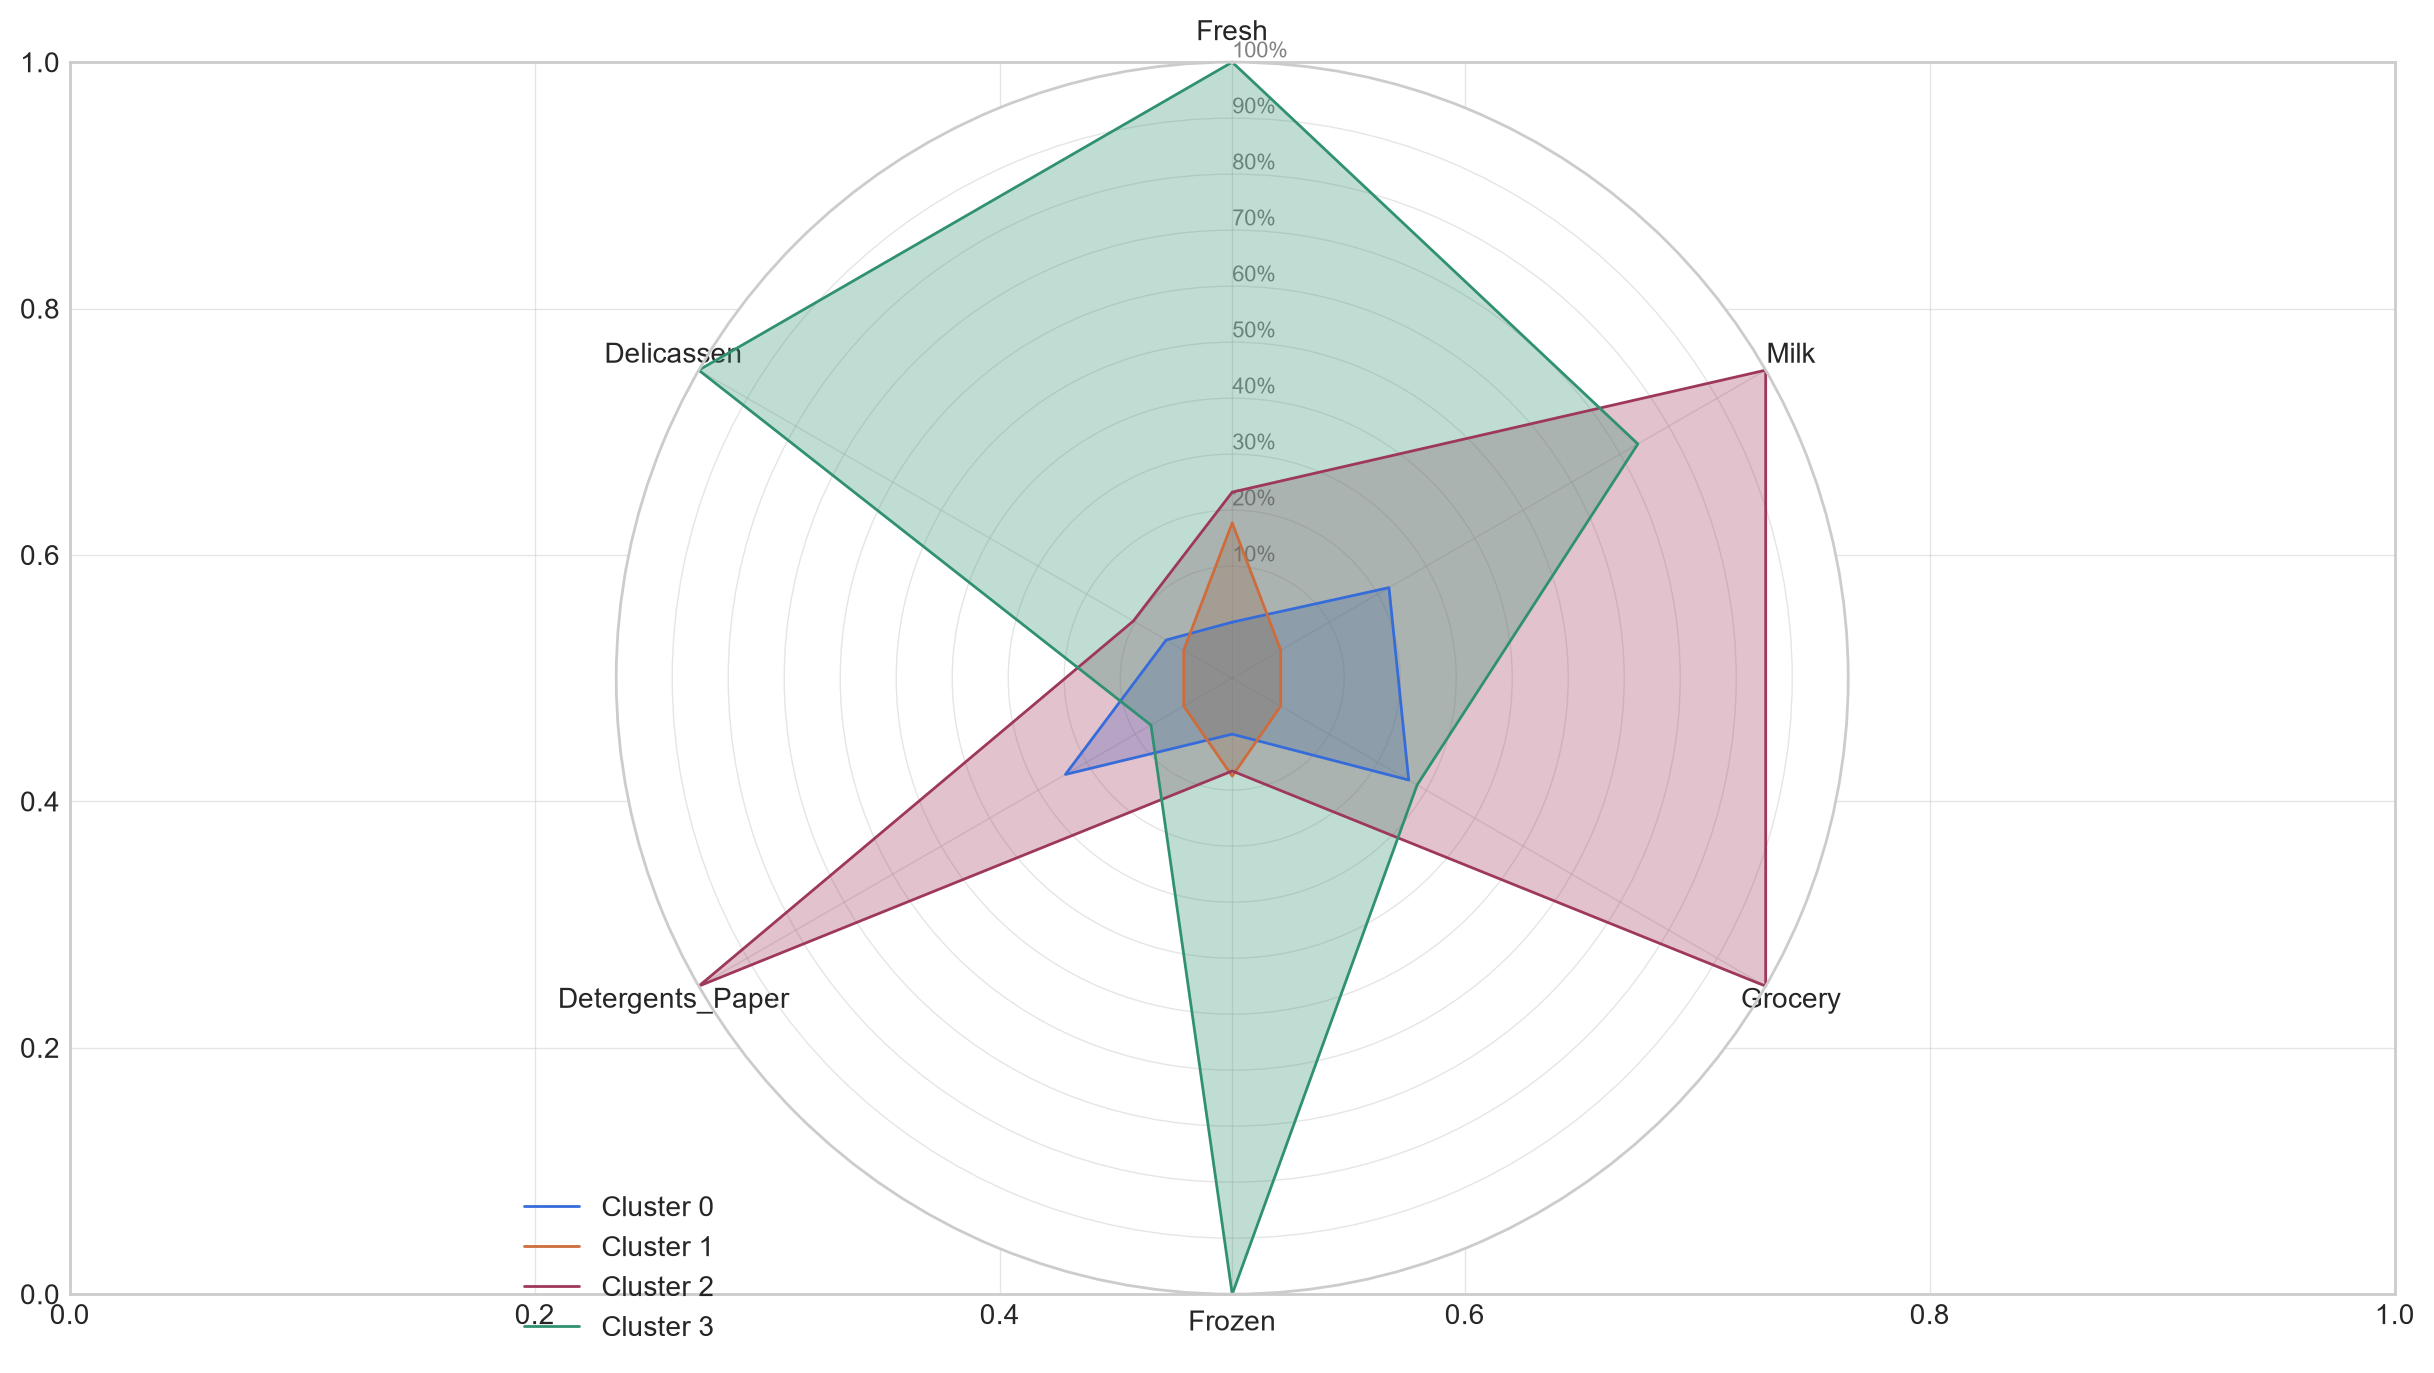

In [29]:
ns.radar_plot(centros, datos_std.columns)
plt.show()

### Promedios en la escala original y composición por canal y región

In [30]:
datos["Cluster_KM"] = grupos_km
datos.groupby("Cluster_KM")[datos_numericos.columns].mean().round(2)

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster_KM,,,,,,
0,5591.44,10113.03,15637.39,1499.92,6711.35,1759.09
1,13504.99,3044.54,3844.44,3271.43,852.32,1127.11
2,15964.90,34708.50,48536.90,3054.60,24875.20,2942.80
3,50270.60,26361.80,16416.00,25122.80,2475.00,18595.20


In [31]:
pd.crosstab(datos["Cluster_KM"], datos["Channel"])

Channel,Horeca,Retail
Cluster_KM,,
0,17,93
1,277,38
2,0,10
3,4,1


In [32]:
pd.crosstab(datos["Cluster_KM"], datos["Region"])

Region,Lisboa,Oporto,Otra
Cluster_KM,,,
0,18,13,79
1,57,32,226
2,2,1,7
3,0,1,4


### Clústeres sobre el plano principal del ACP

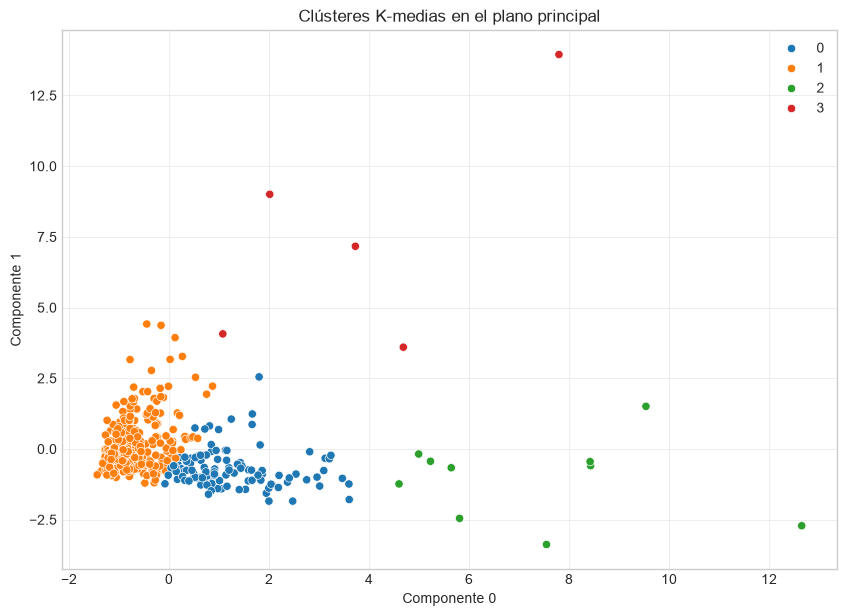

In [33]:
fig, ax = plt.subplots(1, 1, figsize = (10,7), dpi = 100)
coord = acp.coordenadas_ind
sns.scatterplot(x = coord[0], y = coord[1], hue = grupos_km, palette = "tab10", ax = ax)
ax.set_xlabel("Componente 0")
ax.set_ylabel("Componente 1")
ax.set_title("Clústeres K-medias en el plano principal")
plt.show()

**Interpretación de los clústeres K-medias (K = 4):**

- **Cluster 0 – Minoristas (Retail) típicos (110 clientes):** gasto alto en `Grocery` (~15 600), `Milk` (~10 100) y `Detergents_Paper` (~6 700), y bajo en `Fresh` y `Frozen`. El 85 % pertenece al canal Retail.
- **Cluster 1 – Horeca típicos (315 clientes):** es el grupo más grande. Su gasto se concentra en `Fresh` (~13 500) y `Frozen` (~3 300), con montos bajos en abarrotes, lácteos y detergentes. El 88 % pertenece al canal Horeca.
- **Cluster 2 – Grandes minoristas (10 clientes):** todos del canal Retail. Tienen montos muy altos en `Grocery` (~48 500), `Milk` (~34 700) y `Detergents_Paper` (~24 900); podrían ser supermercados o cadenas grandes.
- **Cluster 3 – Grandes compradores de frescos y delicatessen (5 clientes):** gasto extremadamente alto en `Fresh` (~50 300), `Frozen` (~25 100) y `Delicassen` (~18 600), y también alto en `Milk` (~26 400), pero bajo en `Detergents_Paper`; 4 de 5 son Horeca (por ejemplo, hoteles o cadenas de restaurantes grandes).

La **región no diferencia** a los grupos: en todos los clústeres predomina "Otra" en una proporción similar a la del total. En el plano principal se ve que el Cluster 0 y el 2 se extienden hacia el eje de *Retail*, mientras que el 3 lo hace hacia el eje de *Horeca*.

## 4. Clusterización jerárquica (comparación)

In [34]:
ward_res = ward(datos_std)          #Ward
average_res = average(datos_std)    #Promedio
single_res  = single(datos_std)     #Salto mínimo
complete_res = complete(datos_std)  #Salto Máximo

### Salto mínimo, salto máximo y promedio

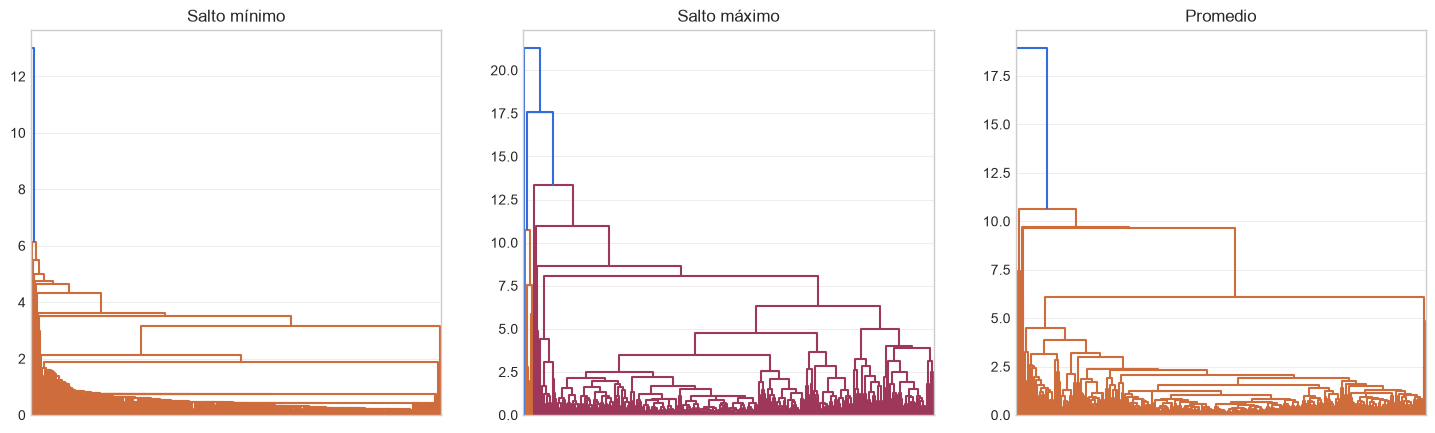

In [35]:
fig, ax = plt.subplots(1, 3, figsize = (18,5), dpi = 100)
dendrogram(single_res, no_labels = True, ax = ax[0])
ax[0].set_title("Salto mínimo")
dendrogram(complete_res, no_labels = True, ax = ax[1])
ax[1].set_title("Salto máximo")
dendrogram(average_res, no_labels = True, ax = ax[2])
ax[2].set_title("Promedio")
plt.show()

Con **salto mínimo** se forma un efecto de "cadena" (los clientes se van uniendo uno a uno) y con **promedio** pasa algo similar: ambos solo separan a los clientes atípicos. El **salto máximo** forma grupos algo más balanceados. Por eso se utiliza el método de **Ward**, que minimiza la varianza dentro de los grupos y es el más parecido a K-medias.

### Ward

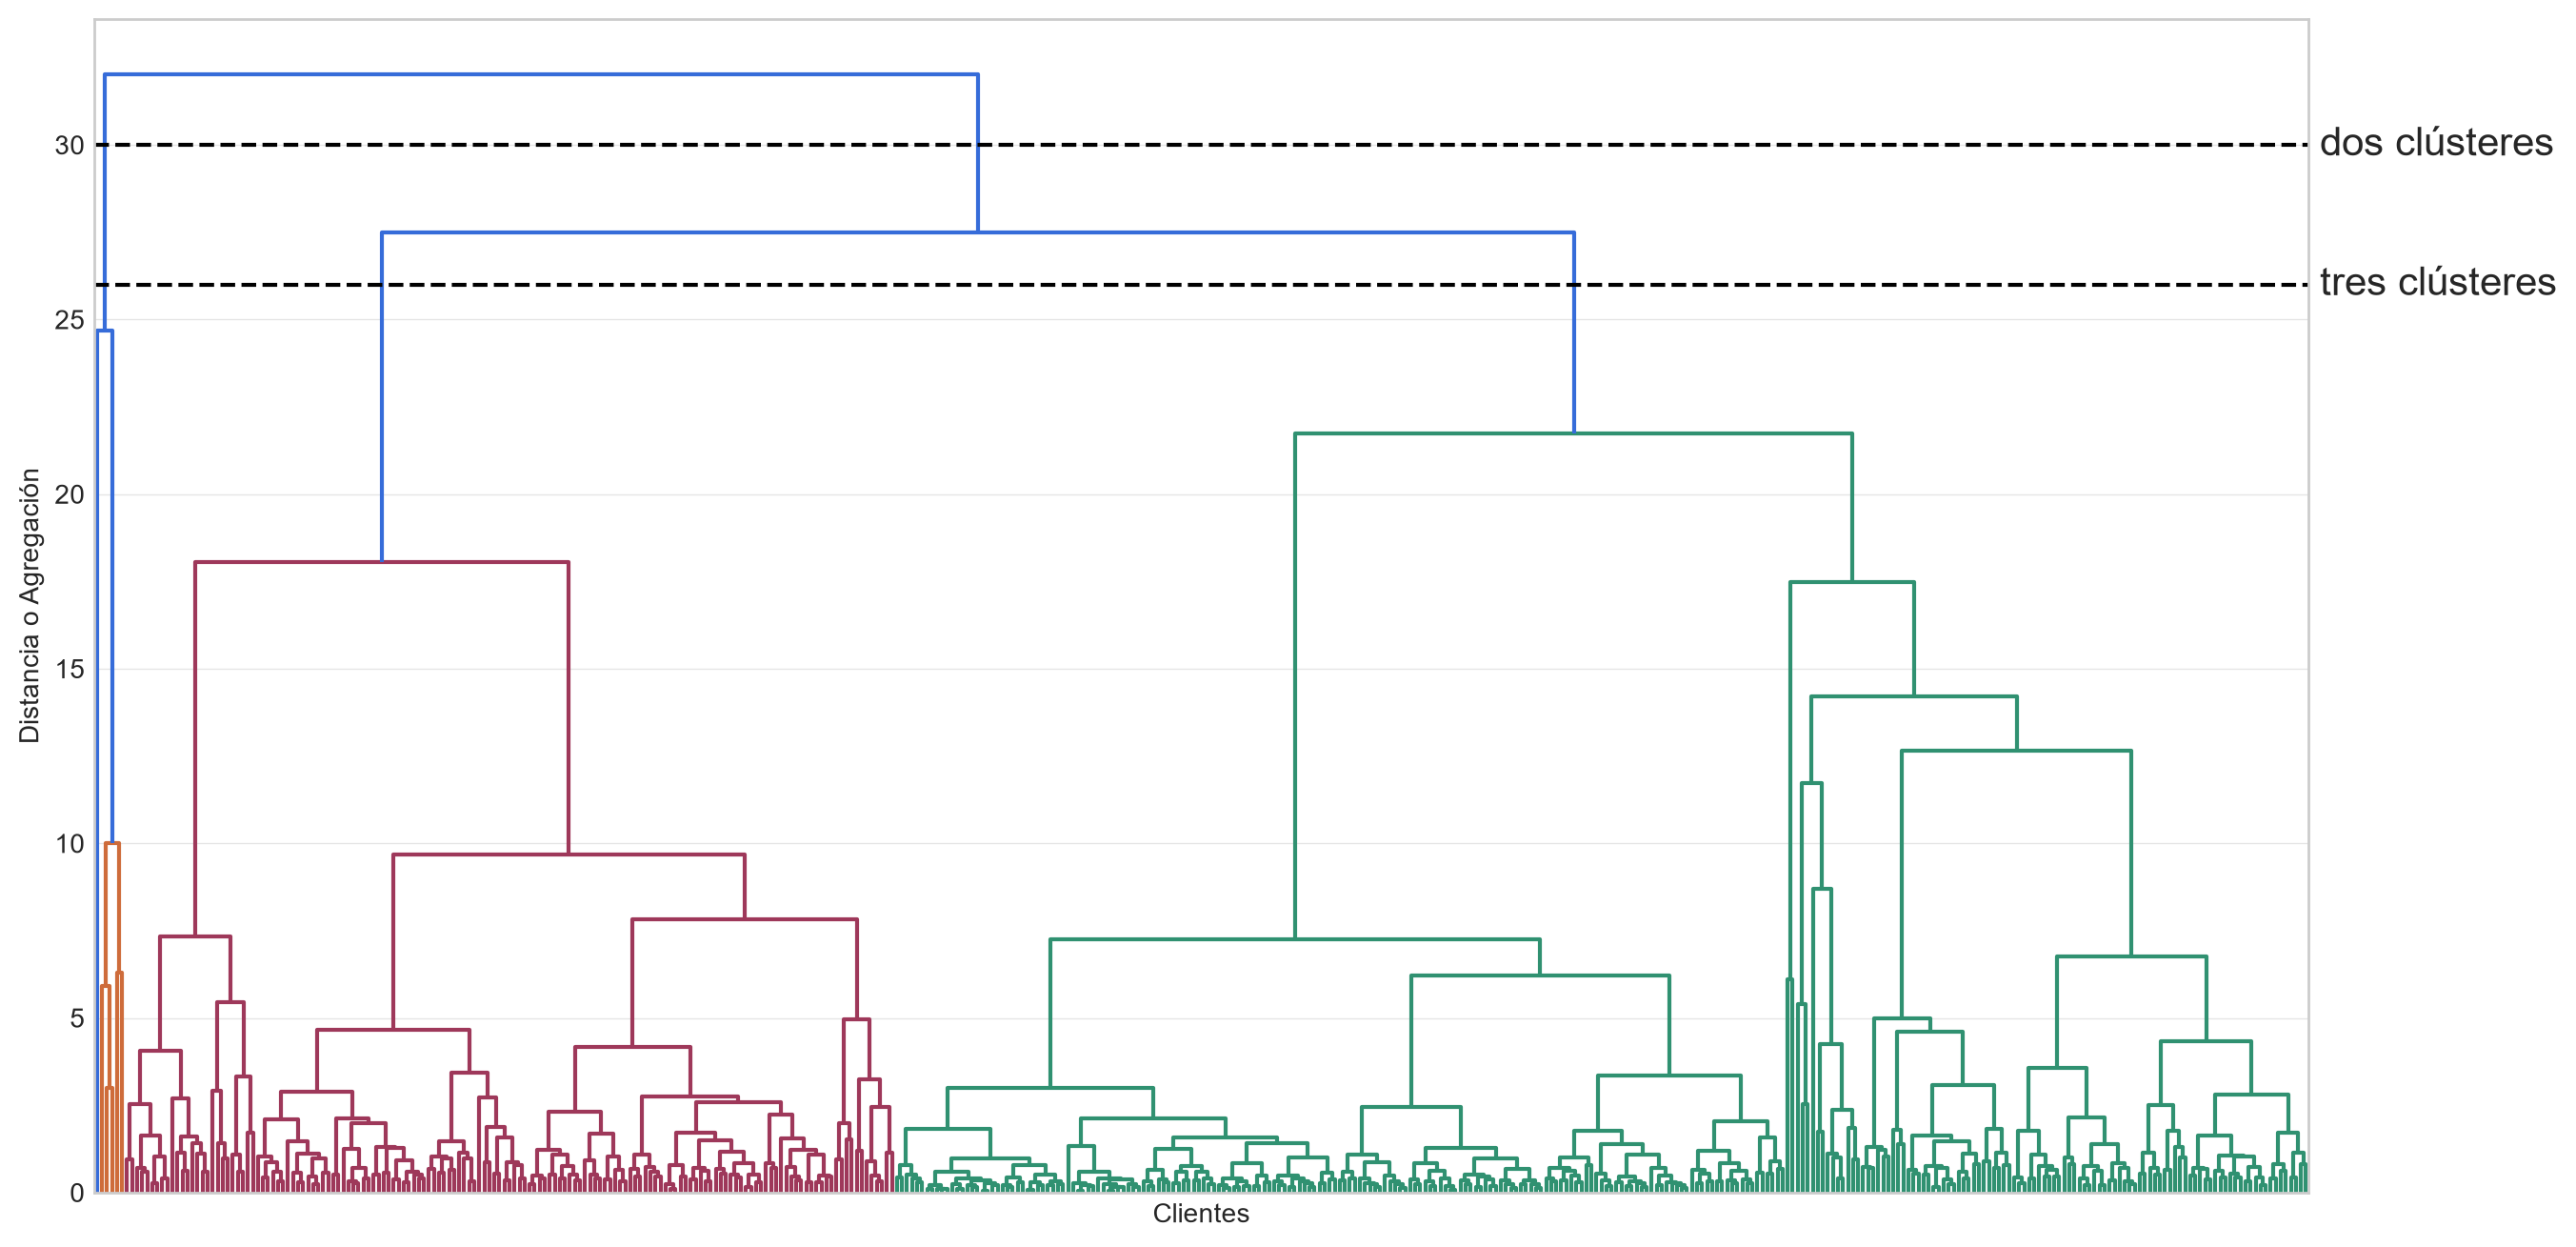

In [36]:
fig, ax = plt.subplots(1, 1, figsize = (15,8), dpi = 200)
dendrogram(ward_res, no_labels = True, ax = ax)

# Agrega cortes con 2 y 3 clústeres con agregación de Ward
limites = ax.get_xbound()
ax.plot(limites, [30, 30], '--', c='k')
ax.plot(limites, [26, 26], '--', c='k')
ax.text(limites[1], 30, ' dos clústeres', va = 'center', fontdict={'size': 15})
ax.text(limites[1], 26, ' tres clústeres', va = 'center', fontdict={'size': 15})
ax.set_xlabel("Clientes")
ax.set_ylabel("Distancia o Agregación")
plt.show()

In [37]:
grupos_h = fcluster(linkage(datos_std, method = 'ward', metric='euclidean'), 3, criterion = 'maxclust')
grupos_h = grupos_h-1 # Se resta 1 para que los clústeres se enumeren de 0 a (K-1), como usualmente lo hace Python
pd.Series(grupos_h).value_counts().sort_index()

0      6
1    153
2    281
Name: count, dtype: int64

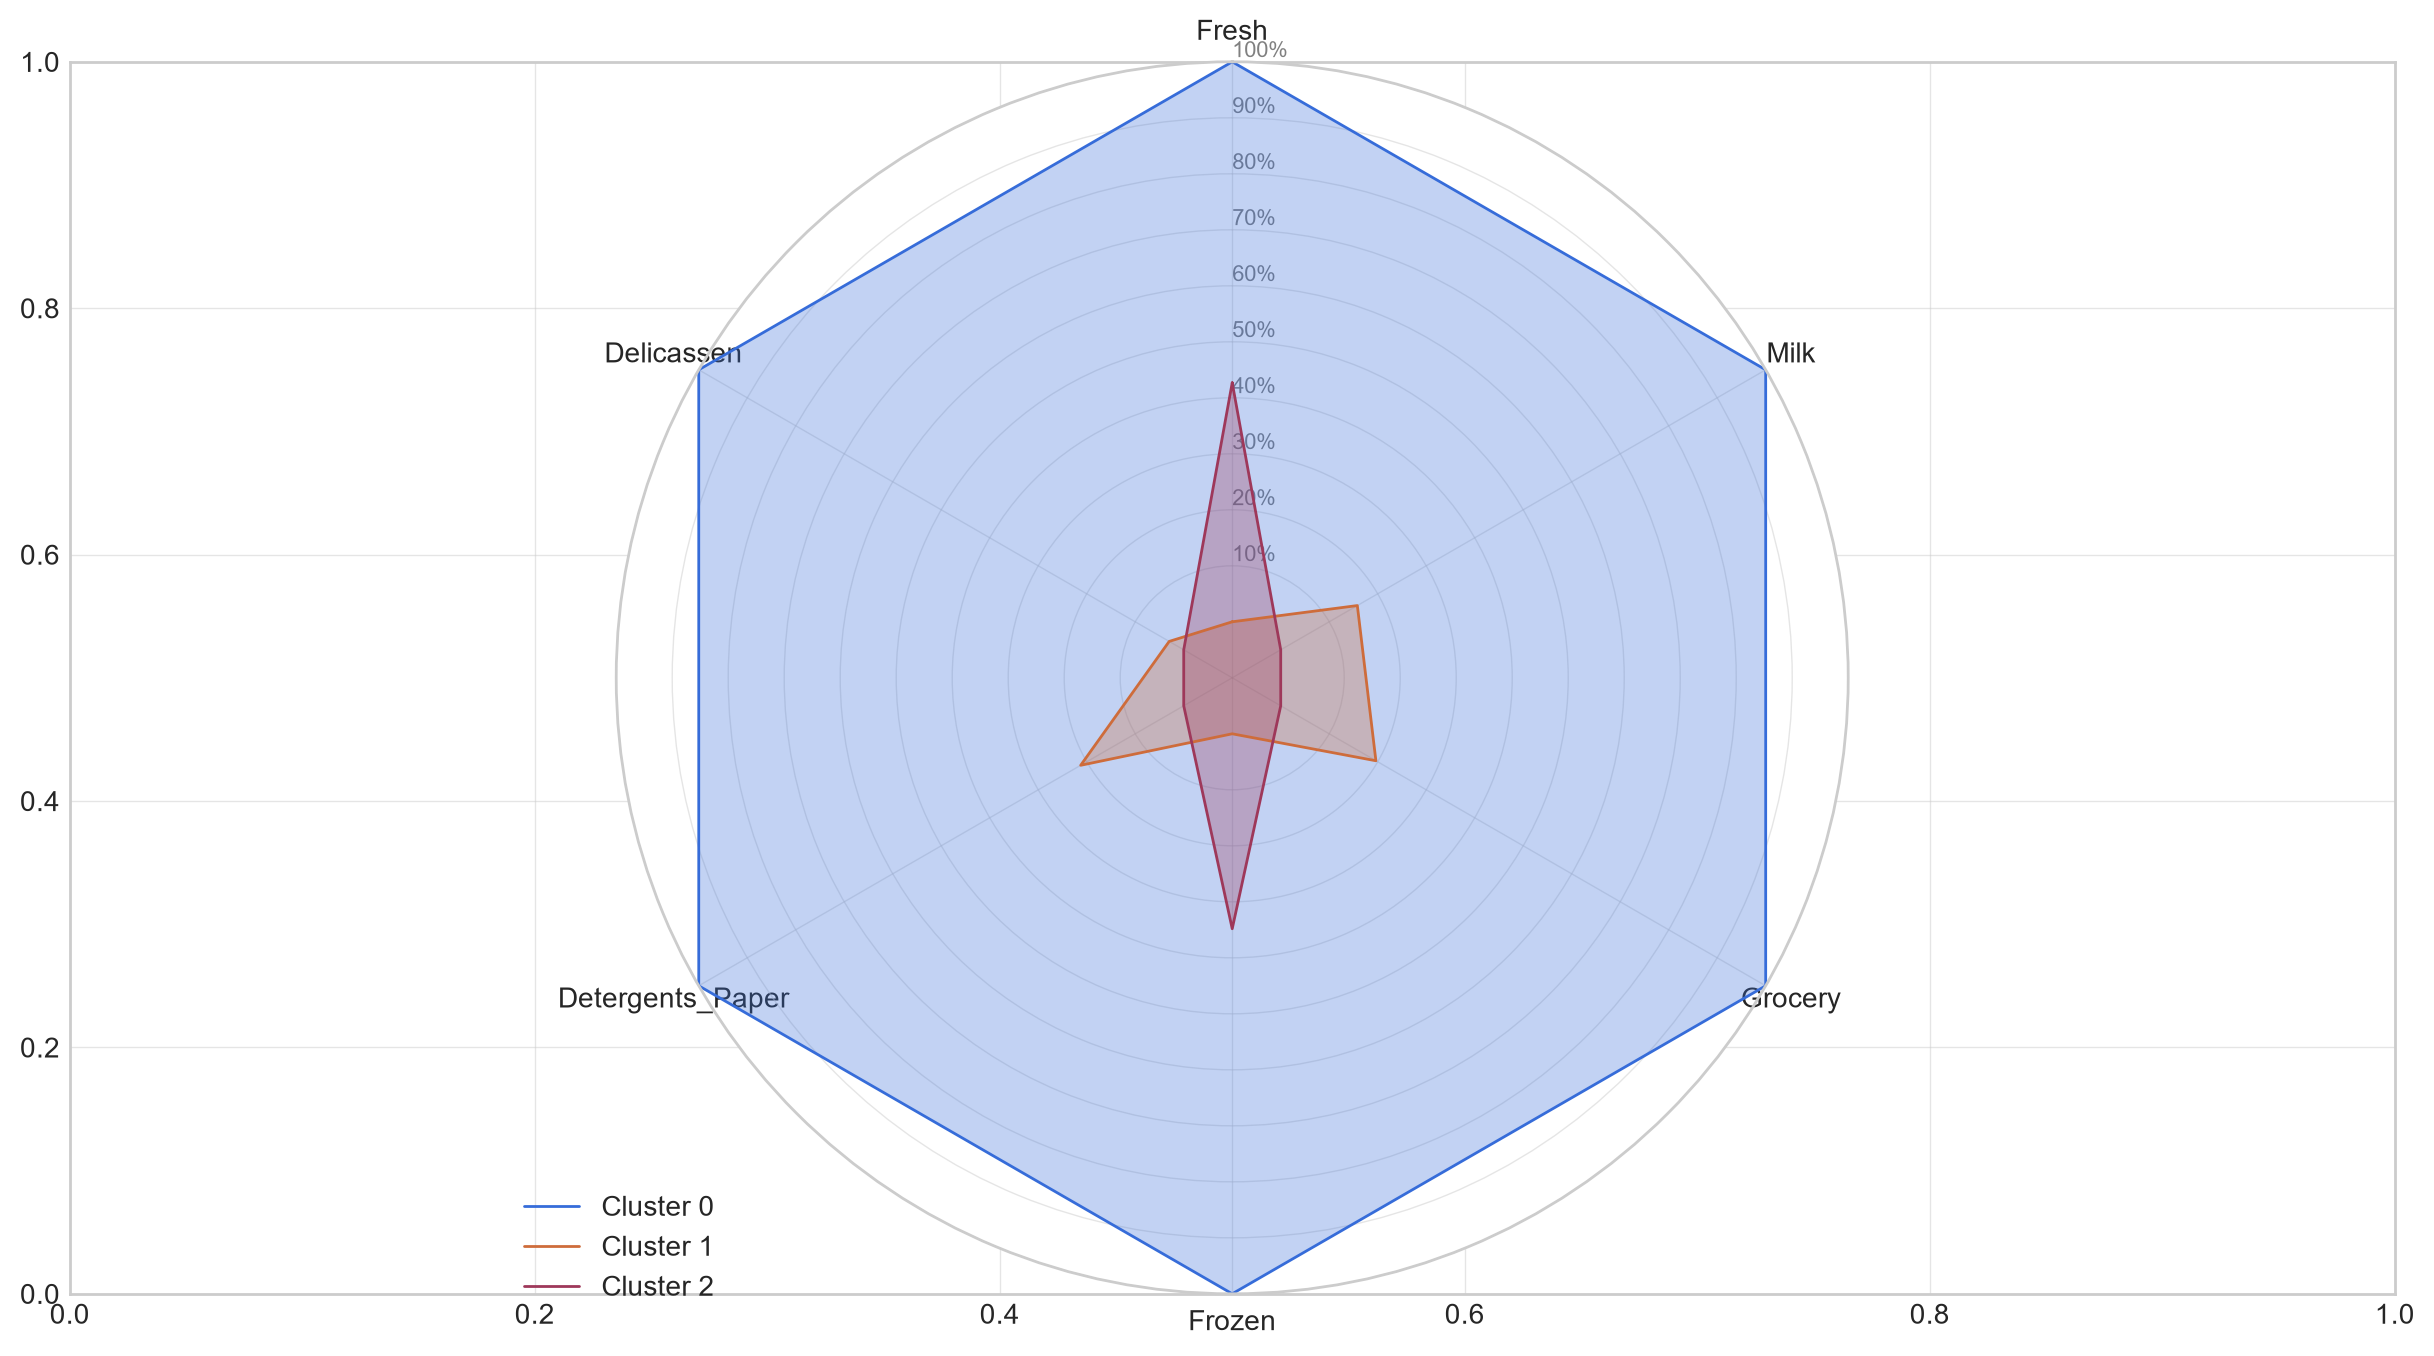

In [38]:
centros_h = np.array(pd.concat([ns.centroide(0, datos_std, grupos_h),
                                ns.centroide(1, datos_std, grupos_h),
                                ns.centroide(2, datos_std, grupos_h)]))
ns.radar_plot(centros_h, datos_std.columns)
plt.show()

In [39]:
datos["Cluster_H"] = grupos_h
datos.groupby("Cluster_H")[datos_numericos.columns].mean().round(2)

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster_H,,,,,,
0,27477.00,43542.17,54588.50,8285.67,25018.33,10247.83
1,5794.24,9419.89,13761.74,1461.76,5913.38,1577.61
2,15048.93,3017.30,3791.76,3837.32,758.01,1309.90


### Comparación K-medias vs Jerárquico (Ward)

In [40]:
pd.crosstab(datos["Cluster_KM"], datos["Cluster_H"], rownames=["K-medias"], colnames=["Ward"])

Ward,0,1,2
K-medias,,,
0,0,105,5
1,0,43,272
2,5,5,0
3,1,0,4


**Ward con 3 clústeres:**
- **Cluster 0 (6 clientes):** grandes compradores con gasto muy alto en todas las categorías, sobre todo `Grocery`, `Milk` y `Detergents_Paper`.
- **Cluster 1 (153 clientes):** perfil *Retail* (abarrotes, lácteos y detergentes); 113 son Retail.
- **Cluster 2 (281 clientes):** perfil *Horeca* (frescos y congelados); 257 son Horeca.

**Comparación:** ambos métodos coinciden en la segmentación principal: el Cluster 1 de K-medias (Horeca) coincide en su mayoría con el Cluster 2 de Ward (272 de 315), y el Cluster 0 de K-medias (Retail) cae casi por completo en el Cluster 1 de Ward (105 de 110). La diferencia principal está en los clientes atípicos: K-medias los separa en dos grupos (grandes minoristas y grandes compradores de frescos), mientras que Ward los mezcla en uno solo o los asigna a los grupos grandes. Además, Ward pone más clientes en el grupo Retail (153 vs 110).

## 5. Conclusiones
1. El set de datos tiene 440 clientes, sin valores nulos ni duplicados, con 6 variables numéricas de gasto y 2 variables categóricas (`Channel`, `Region`) que se usaron solo para interpretar.
2. Las variables de gasto son muy asimétricas, tienen escalas distintas y muchos atípicos; por eso se **estandarizaron** antes de aplicar métodos basados en distancia euclidiana.
3. El ACP y la matriz de correlación muestran dos patrones de compra: uno de **abarrotes, lácteos y detergentes** (Retail) y otro de **frescos, congelados y delicatessen** (Horeca).
4. K-medias con **K = 4** encuentra dos segmentos principales (Horeca típicos y Retail típicos) y dos segmentos pequeños de clientes de gran volumen, que el negocio podría atender de forma diferenciada (por ejemplo, con precios por volumen o atención personalizada).
5. El método jerárquico de Ward confirma la segmentación principal Horeca/Retail, lo que da confianza en los resultados.
6. La región no resultó relevante para diferenciar a los clientes; el patrón de compra está mucho más ligado al **canal**.

In [41]:
datos.to_csv("Wholesale_clusters.csv", index = False)